# Tentativo 18 · 3. Un BERT addestrato come regressore

Il transformer si addestra tutto (tutti i pesi) a prevedere il punteggio/100, con l'errore quadratico pesato secondo la
condizione (A, B, C, D come nel notebook 2), 5 epoche, learning rate 3e-5, lotti di 32, nessuna validazione (si tiene
l'ultima epoca). Il test sono tutti gli articoli delle testate del fold. Si lancia una volta per modello e condizione,
sullo split 1:
- **ModernBERT-base** (150 M di parametri, articoli interi fino a 2.048 token);
- **DeBERTa-v3-base** (184 M di parametri, i primi 512 token: un'architettura diversa, molto forte nella regressione).

In [1]:
T16_DIR = "../16_DataPreparation"
MODELLO = "answerdotai/ModernBERT-base"
NOME = "ModernBERT"
CONDIZIONE = "B"
SPLIT = 1
MAX_TOKEN = 2048
EPOCHE = 5
LR = 3e-5
GB_GPU = 14
PROVA = 0                                   # > 0: solo quel numero di articoli per testata e 1 epoca (prova veloce)

In [2]:
# Parameters
T16_DIR = "/home/fabio.pinelli/John/Tentativo16"
MODELLO = "microsoft/deberta-v3-base"
NOME = "DeBERTa"
MAX_TOKEN = 512
CONDIZIONE = "B"
EPOCHE = 5


In [3]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

T16 = Path(T16_DIR).expanduser(); sys.path.insert(0, str(T16))
import funzioni as F16                      # il tentativo 16: dataset e cartella dei dati
import punteggio as P

warnings.filterwarnings("ignore")
plt.rcParams.update(F16.STILE_GRAFICI)
BLU, ARANCIO, GRIGIO, CHIARO, VERDE, ROSSO = "#2a78d6", "#eb6834", "#52514e", "#b5b3ab", "#1baf7a", "#b02a2a"
DATI18 = F16.DATI / "tentativi" / "18_PunteggioEsatto"; DATI18.mkdir(parents=True, exist_ok=True)
OUT = Path("Results"); OUT.mkdir(exist_ok=True)
art = pd.read_csv(F16.DATASET / "articoli.csv.gz")
t = pd.read_csv(F16.DATASET / "testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate")

25,524 articoli di 226 testate


In [4]:
import time
split = pd.read_csv(DATI18 / "split.csv", index_col=0).reindex(t.index)
fold = split[f"split{SPLIT}"]
art["score"] = t.score.reindex(art.domain).to_numpy()
cartella = OUT / ("prova" if PROVA else "") / "bert" / f"{NOME}_{CONDIZIONE}"; cartella.mkdir(parents=True, exist_ok=True)
if PROVA:
    art = art.groupby("domain").head(PROVA).reset_index(drop=True); EPOCHE = 1
log = open(OUT / "bert_avanzamento.log", "a")
def registra(m):
    riga = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {NOME} {CONDIZIONE}: {m}"; print(riga, flush=True); log.write(riga + "\n"); log.flush()
pezzi = [P.bert_fold(art, fold, k, CONDIZIONE, MODELLO, cartella, registra, MAX_TOKEN, epoche=EPOCHE, lr=LR, gb_gpu=GB_GPU) for k in range(1, 6)]
prev = pd.concat(pezzi, ignore_index=True).assign(modello=NOME, split=f"split{SPLIT}", condizione=CONDIZIONE, tipo="regressore")
prev.to_csv(cartella / "previsioni.csv.gz", index=False)
print(f"{len(prev):,} articoli previsti")

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-30 00:13:08  DeBERTa B: fold 1, epoca 1/5: loss 0.0707 (449 s)


2026-10-30 00:20:35  DeBERTa B: fold 1, epoca 2/5: loss 0.0269 (895 s)


2026-10-30 00:28:01  DeBERTa B: fold 1, epoca 3/5: loss 0.0166 (1342 s)


2026-10-30 00:35:27  DeBERTa B: fold 1, epoca 4/5: loss 0.0107 (1787 s)


...

2026-10-30 03:08:36  DeBERTa B: fold 5, epoca 3/5: loss 0.0166 (1295 s)


2026-10-30 03:15:48  DeBERTa B: fold 5, epoca 4/5: loss 0.0110 (1727 s)


2026-10-30 03:22:59  DeBERTa B: fold 5, epoca 5/5: loss 0.0075 (2158 s)


2026-10-30 03:23:41  DeBERTa B: fold 5: finito, memoria GPU massima 5.6 GB


25,524 articoli previsti


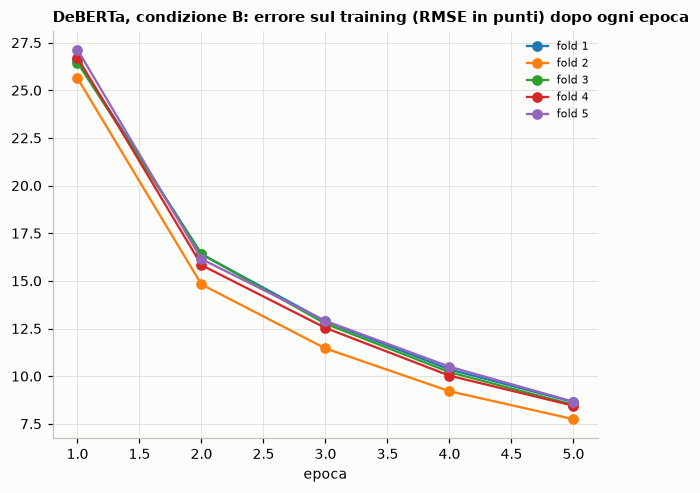

In [5]:
curve = pd.concat([pd.read_csv(cartella / f"curva_fold{k}.csv").assign(fold=k) for k in range(1, 6)])
for k, c in curve.groupby("fold"):
    plt.plot(c.epoca, np.sqrt(c.loss) * 100, marker="o", label=f"fold {k}")
plt.title(f"{NOME}, condizione {CONDIZIONE}: errore sul training (RMSE in punti) dopo ogni epoca"); plt.xlabel("epoca"); plt.legend(fontsize=7)
plt.savefig(cartella / "curve.png", dpi=150, bbox_inches="tight"); plt.show()